## Setup

In [58]:
# pip install nltk textblob wordcloud vaderSentiment

In [59]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud, STOPWORDS

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

## Import Data

In [60]:
df = pd.read_csv("Tweets.csv")
df = df[['tweet_id', 'airline_sentiment', 'airline', 'text']]

df.head()

,tweet_id,airline_sentiment,airline,text
0,570306133677760513,neutral,Virgin America,@VirginAmerica What @dhepburn said.
1,570301130888122368,positive,Virgin America,@VirginAmerica plus you've added commercials t...
2,570301083672813571,neutral,Virgin America,@VirginAmerica I didn't today... Must mean I n...
3,570301031407624196,negative,Virgin America,@VirginAmerica it's really aggressive to blast...
4,570300817074462722,negative,Virgin America,@VirginAmerica and it's a really big bad thing...


In [61]:
LABELS = ["negative", "neutral", "positive"]

## EDA

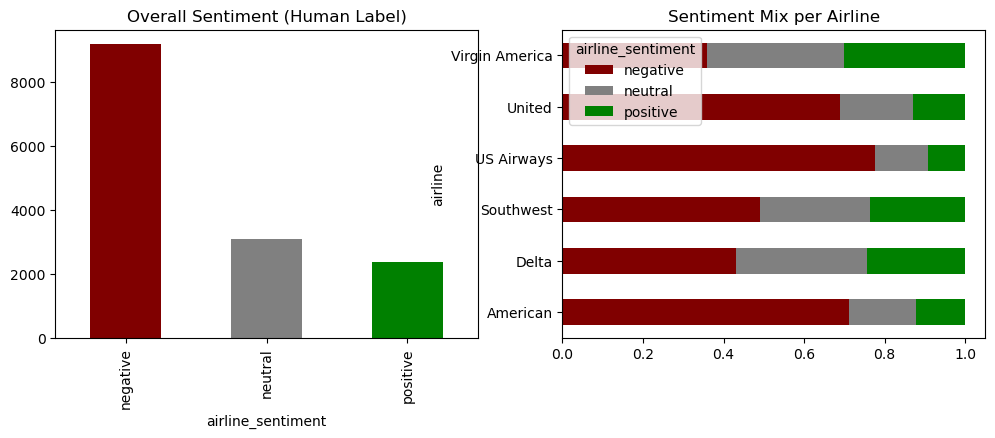

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

df['airline_sentiment'].value_counts().reindex(LABELS).plot.bar(
    ax=axes[0], color=['maroon', 'gray', 'green'])
axes[0].set_title("Overall Sentiment (Human Label)")

pd.crosstab(df["airline"], df['airline_sentiment'], normalize="index")[LABELS].plot.barh(
    stacked=True, ax=axes[1], color=['maroon', 'gray', 'green'])
axes[1].set_title("Sentiment Mix per Airline")
plt.show()

In [63]:
def clean_tweet(text):
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # URLs
    text = re.sub(r"@\w+", " ", text)               # @mentions (airline handles)
    text = text.replace("&amp;", "&").replace("#", "")
    return re.sub(r"\s+", " ", text).strip()

df['clean'] = df["text"].apply(clean_tweet)
df[['text', 'clean']].sample(5)

,text,clean
6435,@SouthwestAir Hi! I just saw a Black History m...,Hi! I just saw a Black History month commercia...
14013,@AmericanAir is profiting in the billions and ...,is profiting in the billions and throwing crap...
2831,@united just landed. Might want to check fligh...,just landed. Might want to check flight 304 pl...
9651,"@USAirways And by the way, I'm planning it whi...","And by the way, I'm planning it while I've Ben..."
4260,@united is Late Flight again. Everyone braved...,is Late Flight again. Everyone braved the weat...


### WordCloud

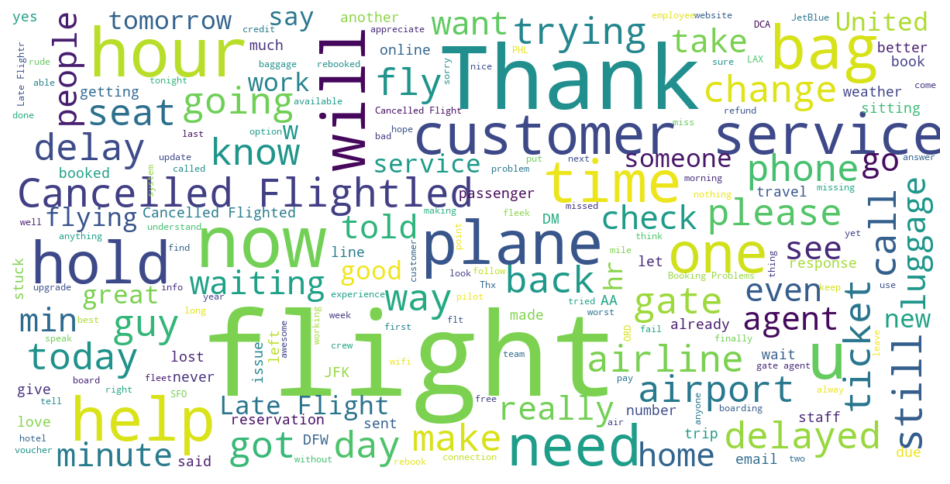

In [64]:
tweets = df['clean'].str.cat(sep=" ")

all_stopwords = STOPWORDS

wordcloud = WordCloud(
    background_color = 'white',
    stopwords = all_stopwords,
    max_words = 200,
    max_font_size = 50,
    scale = 3,
    random_state = 1
).generate(tweets)

plt.figure(figsize=(12,12))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

## Train/Test Split

In [65]:
train, test = train_test_split(df, test_size=0.2, random_state=42,
                                stratify=df["airline_sentiment"])

y_train = train['airline_sentiment'].to_numpy()
y_test = test['airline_sentiment'].to_numpy()

print(len(train), 'train data; ', len(test), 'test data')

results, preds = {}, {}

11712 train data;  2928 test data


In [66]:
def evaluate(name, y_pred):
    y_pred=np.asarray(y_pred)
    preds[name] = y_pred

    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, labels=LABELS, average="macro") 
    }

    print(f"==={name}===")
    print(classification_report(y_test, y_pred, labels=LABELS, digits=3, zero_division=0))

## Model 1: VADER - lexicon + rules, built for social media 

#### VADER Examples

In [67]:
vader = SentimentIntensityAnalyzer()

examples = [
    "The flight was good.",
    "The flight was GOOD!!!",
    "The flight was not good.",
    "The flight was very good, but the food was terrible.",
    "Lost my bag again :(",
    "Thanks for the upgrade :)",
]

In [68]:
pd.DataFrame(
    [{"text": s, **vader.polarity_scores(s)} for s in examples]
).round(3)

,text,neg,neu,pos,compound
0,The flight was good.,0.000,0.508,0.492,0.440
1,The flight was GOOD!!!,0.000,0.400,0.600,0.671
2,The flight was not good.,0.376,0.624,0.000,-0.341
3,"The flight was very good, but the food was ter...",0.291,0.562,0.147,-0.468
4,Lost my bag again :(,0.634,0.366,0.000,-0.637
5,Thanks for the upgrade :),0.000,0.337,0.663,0.710


### Main Model

In [69]:
def vader_label(text, threshold=0.2):
    c = vader.polarity_scores(text)['compound']

    if c >= threshold:
        return "positive"
    elif c <= -threshold:
        return "negative"
    else:
        return "neutral"

In [70]:
evaluate("VADER", test['clean'].apply(vader_label))

===VADER===
              precision    recall  f1-score   support

    negative      0.905     0.457     0.607      1835
     neutral      0.342     0.503     0.407       620
    positive      0.381     0.877     0.531       473

    accuracy                          0.534      2928
   macro avg      0.543     0.612     0.515      2928
weighted avg      0.701     0.534     0.552      2928



In [71]:
results

{'VADER': {'accuracy': 0.5344945355191257, 'macro_f1': 0.515122405011359}}

## Model 2: TextBlob - General Purpose Lexicon

#### sentiment - polarity;  subjectivity

In [72]:
examples = [
    "The flight was good.",
    "The flight was GOOD!!!",
    "The flight was not good.",
    "The flight was very good, but the food was terrible.",
    "Lost my bag again :(",
    "Thanks for the upgrade :)",
    "So great! So life changing!"
]

### TextBlob Examples

In [73]:
pd.DataFrame(
    [{
        "text": s,
        "polarity": TextBlob(s).sentiment.polarity,
        "subjectivity": TextBlob(s).sentiment.subjectivity}
        for s in examples]
)

,text,polarity,subjectivity
0,The flight was good.,0.700,0.60
1,The flight was GOOD!!!,1.000,0.60
2,The flight was not good.,-0.350,0.60
3,"The flight was very good, but the food was ter...",-0.045,0.89
4,Lost my bag again :(,-0.750,1.00
5,Thanks for the upgrade :),0.350,0.60
6,So great! So life changing!,1.000,0.75


### Main Model

In [74]:
def textblob_label(text, threshold=0.2):
    p = TextBlob(text).sentiment.polarity
    if p >= threshold:
        return "positive"
    elif p <= -threshold:
        return "negative"
    else:
        return "neutral"

In [75]:
evaluate("TextBlob", test['clean'].apply(textblob_label))

===TextBlob===
              precision    recall  f1-score   support

    negative      0.917     0.222     0.358      1835
     neutral      0.270     0.737     0.395       620
    positive      0.404     0.672     0.504       473

    accuracy                          0.404      2928
   macro avg      0.530     0.544     0.419      2928
weighted avg      0.697     0.404     0.389      2928



## Model 3: NLTK + Naive Bayes

In [76]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Patrick\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [77]:
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.sentiment.util import mark_negation
from nltk import NaiveBayesClassifier, FreqDist

In [78]:
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=True)

KEEP = {"no", "nor", "not", "very", "too", "against"}
STOP = {w for w in stopwords.words("english") if w not in KEEP and "n't" not in w}

In [79]:
def tweet_tokens(text):
    toks = tokenizer.tokenize(text)
    toks = mark_negation(toks)
    return [t for t in toks
            if t.replace("_NEG", "") not in STOP and re.search(r"\w", t)]

In [80]:
print(tweet_tokens("I do Not like this airline, the delay was too long!!!"))

['not', 'like_NEG', 'airline_NEG', ',_NEG', 'delay_NEG', 'too_NEG', 'long_NEG']


### Main Model

In [81]:
train_tokens = [tweet_tokens(t) for t in train['clean']]
test_tokens = [tweet_tokens(t) for t in test['clean']]

In [82]:
freq = FreqDist(w for toks in train_tokens for w in toks)
VOCAB = {w for w, _ in freq.most_common(3000)}

In [83]:
def nltk_features(tokens):
    return {w: True for w in set(tokens) if w in VOCAB} # bag-of-words

In [84]:
train_set = [(nltk_features(t), y) for t, y in zip(train_tokens, y_train)]
nb = NaiveBayesClassifier.train(train_set)
nb.show_most_informative_features(20)

Most Informative Features
                   kudos = True           positi : negati =     47.9 : 1.0
               fantastic = True           positi : negati =     40.1 : 1.0
                favorite = True           positi : negati =     35.0 : 1.0
                  safely = True           positi : negati =     32.4 : 1.0
                      <3 = True           positi : negati =     29.8 : 1.0
             outstanding = True           positi : negati =     27.2 : 1.0
                passbook = True           positi : negati =     27.2 : 1.0
                   raise = True           positi : negati =     27.2 : 1.0
                 amazing = True           positi : negati =     26.4 : 1.0
                 helpful = True           positi : neutra =     25.8 : 1.0
                     hrs = True           negati : positi =     25.1 : 1.0
                    rock = True           positi : negati =     25.0 : 1.0
                   flyfi = True           positi : negati =     24.6 : 1.0

In [85]:
evaluate("NLTK + Naive Bayes", [nb.classify(nltk_features(t)) for t in test_tokens])

===NLTK + Naive Bayes===
              precision    recall  f1-score   support

    negative      0.775     0.968     0.861      1835
     neutral      0.739     0.319     0.446       620
    positive      0.783     0.611     0.686       473

    accuracy                          0.773      2928
   macro avg      0.766     0.633     0.664      2928
weighted avg      0.769     0.773     0.745      2928



## Compare all methods

In [86]:
results

{'VADER': {'accuracy': 0.5344945355191257, 'macro_f1': 0.515122405011359},
 'TextBlob': {'accuracy': 0.40403005464480873, 'macro_f1': 0.41902425643087},
 'NLTK + Naive Bayes': {'accuracy': 0.7728825136612022,
  'macro_f1': 0.6644296546400463}}

In [87]:
summary = pd.DataFrame(results).T.sort_values("macro_f1", ascending=False).round(3)
summary

,accuracy,macro_f1
NLTK + Naive Bayes,0.773,0.664
VADER,0.534,0.515
TextBlob,0.404,0.419


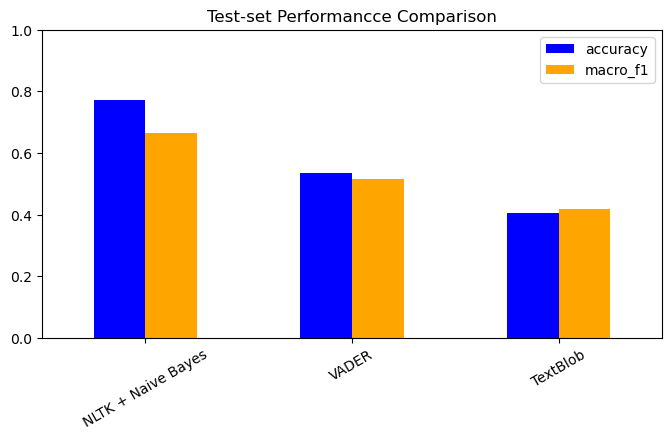

In [88]:
summary.plot.bar(figsize=(8,4), rot=30, color=['blue', 'orange'])
plt.title("Test-set Performancce Comparison")
plt.ylim(0,1)
plt.show()

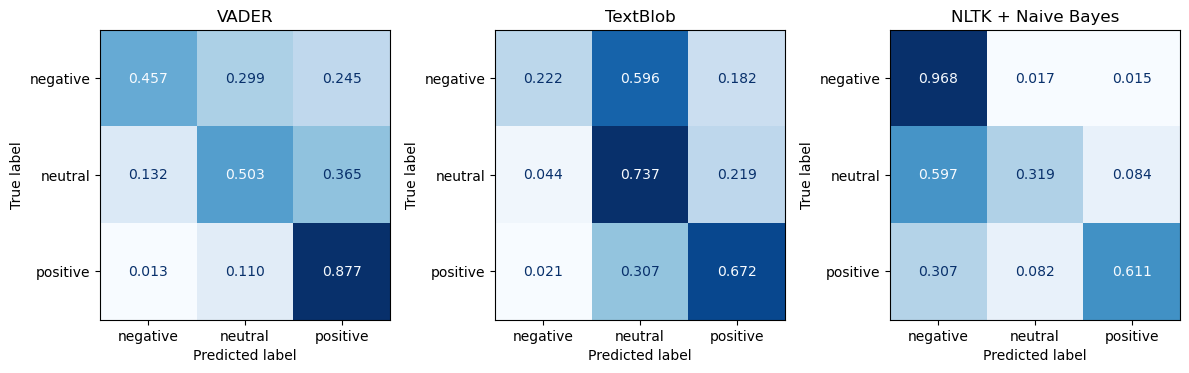

In [100]:
fig, axes = plt.subplots(1, 3, figsize=(12, 9))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, y_pred, labels=LABELS, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".3f")
    ax.set_title(name)

plt.tight_layout()
plt.show()

## Error Analysis

In [98]:
errors = test[['clean', "airline_sentiment"]].copy()
errors['VADER'] = preds["VADER"]
errors['TextBlob'] = preds["TextBlob"]
errors['NLTK + NB'] = preds['NLTK + Naive Bayes']

pd.set_option('display.max_colwidth', 70)
errors.head(15)

,clean,airline_sentiment,VADER,TextBlob,NLTK + NB
2998,past,neutral,neutral,negative,negative
7719,would you say a delay is more likely? Thanks so much.,positive,positive,positive,negative
8575,"I cheated on you, and I'm sorry. I'll never do it again. has given...",negative,negative,negative,negative
618,disappointed that u didnt honor my $100 credit given to me for ur ...,negative,negative,negative,negative
11741,The airline is embarrassing itself. I get that bad weather isn't y...,negative,positive,negative,negative
14246,my flight has been delayed & I can't talk reach anyone in customer...,negative,negative,neutral,negative
4006,This link in your tweet goes to someone's internal email -&gt; Pro...,neutral,positive,neutral,negative
5778,BETSY is the BESTY! Gettin' stuck at LAS might not be bad for most...,negative,positive,negative,negative
9624,How many agents do you have working to handle the thousands of calls?,negative,neutral,positive,negative
4686,When will the flight resume? I don's see it in the open schedule. :/,negative,negative,neutral,neutral


In [99]:
errors.to_csv("tweets_with_sentiment.csv", index=False)